# 02 · Data Quality

Automated quality checks: nulls, duplicates, referential integrity, domain rules, and the cleaning applied.

> Data: Olist Brazilian E-Commerce public dataset (BRL). All narrative under charts is generated from the computed statistics.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import os; os.chdir(ROOT)
import pandas as pd, numpy as np
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)
from src.analytics import eda
om, items, cm, daily = eda.load()

def show(f):
    if f.figure: display(Image(filename=str(ROOT / f.figure)))
    display(Markdown(f"**Business interpretation – {f.title}:** {f.interpretation}"))


## 1. Check summary

In [2]:
chk = pd.read_csv('reports/data_quality/dq_checks.csv')
chk.status.value_counts().to_frame('checks')

,checks
status,
PASS,69
WARN,21
NOTE,10


## 2. Issues (non-passing checks)

In [3]:
chk[chk.status != 'PASS'].sort_values('failed_rows', ascending=False)[['dataset','check','column','failed_rows','failed_pct','status','detail']]

,dataset,check,column,failed_rows,failed_pct,status,detail
16,geolocation,duplicate_full_row,*,261831,26.1788,WARN,NaN
57,reviews,null_check,review_comment_title,87656,88.3415,NOTE,NaN
58,reviews,null_check,review_comment_message,58247,58.7025,NOTE,NaN
32,orders,null_check,order_delivered_customer_date,2965,2.9817,NOTE,NaN
31,orders,null_check,order_delivered_carrier_date,1783,1.7930,NOTE,NaN
92,reviews,duplicate_review_id_across_orders,review_id,814,0.8204,NOTE,Same survey id covers several orders; grain is...
75,orders,orders_without_items,order_id,775,0.7794,WARN,Orders with no order_items rows (mostly cancel...
44,products,null_check,product_category_name,610,1.8512,WARN,NaN
46,products,null_check,product_description_lenght,610,1.8512,WARN,NaN
47,products,null_check,product_photos_qty,610,1.8512,WARN,NaN


## 3. Referential integrity

In [4]:
chk[chk.check == 'referential_integrity'][['dataset','column','detail','failed_rows','status']]

,dataset,column,detail,failed_rows,status
69,orders,customer_id,orders.customer_id -> customers.customer_id,0,PASS
70,order_items,order_id,order_items.order_id -> orders.order_id,0,PASS
71,order_items,product_id,order_items.product_id -> products.product_id,0,PASS
72,order_items,seller_id,order_items.seller_id -> sellers.seller_id,0,PASS
73,payments,order_id,payments.order_id -> orders.order_id,0,PASS
74,reviews,order_id,reviews.order_id -> orders.order_id,0,PASS


## 4. Null profile by column

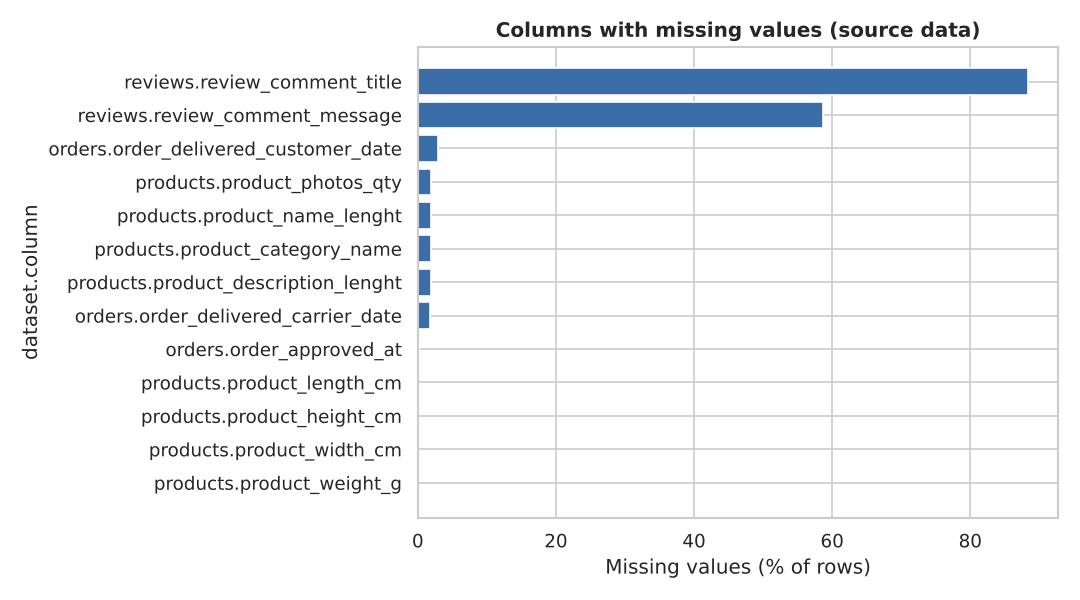

In [5]:
import matplotlib.pyplot as plt
prof = pd.read_csv('reports/data_quality/column_profile.csv')
nz = prof[prof.null_pct > 0].sort_values('null_pct')
fig, ax = plt.subplots(figsize=(9, 5)); ax.barh(nz.dataset + '.' + nz.column, nz.null_pct, color='#3B6EA8')
ax.set(title='Columns with missing values (source data)', xlabel='Missing values (% of rows)', ylabel='dataset.column')
display(Image(filename=str(ROOT / eda._save(fig, '02_missing_values'))))

## 5. Cleaning log (what the ETL changed)

In [6]:
pd.read_csv('reports/data_quality/cleaning_log.csv')

,dataset,action,rows_affected,detail
0,category_translation,append_manual_translations,3,NaN
1,geolocation,drop_duplicates,279694,subset=all columns
2,geolocation,drop_coordinates_outside_brazil,27,NaN
3,geolocation,aggregate_to_zip_prefix,19011,"median lat/lng, modal city/state per prefix"
4,customers,normalize_city,226,"lower-case, accents removed"
5,sellers,normalize_city,12,"lower-case, accents removed"
6,products,fill_missing_category,610,set to 'unknown'
7,products,manual_category_translation,13,"pc_gamer, portateis_cozinha_e_preparadores_de_..."
8,products,zero_weight_to_null,4,weight 0 g treated as unknown
9,orders,null_order_delivered_carrier_date_before_purchase,166,NaN


## 6. SQL ↔ Python reconciliation

In [7]:
p = ROOT / 'reports/sql_results/_reconciliation.csv'
pd.read_csv(p) if p.exists() else 'Run the analytics stage with PostgreSQL first.'

,check,sql_value,python_value,abs_diff,tolerance,status,detail
0,kpi:total_revenue,1.573553e+07,1.573553e+07,0.0,15.735527,PASS,NaN
1,kpi:product_revenue,1.349440e+07,1.349440e+07,0.0,13.494401,PASS,NaN
2,kpi:freight_revenue,2.241126e+06,2.241126e+06,0.0,2.241126,PASS,NaN
3,kpi:total_orders,9.820700e+04,9.820700e+04,0.0,0.000000,PASS,NaN
4,kpi:all_orders,9.944100e+04,9.944100e+04,0.0,0.000000,PASS,NaN
5,kpi:unique_customers,9.499000e+04,9.499000e+04,0.0,0.000000,PASS,NaN
6,kpi:average_order_value,1.602300e+02,1.602300e+02,0.0,0.011000,PASS,NaN
7,kpi:total_payment_value,1.600887e+07,1.600887e+07,0.0,16.008872,PASS,NaN
8,kpi:cancellation_rate,6.285000e-03,6.285000e-03,0.0,0.011000,PASS,NaN
9,kpi:on_time_delivery_rate,9.322690e-01,9.322690e-01,0.0,0.011000,PASS,NaN


**Interpretation.** No primary-key or foreign-key violations exist in the source. The material issues are business-level: orders without items (mostly canceled/unavailable), shipping limits years in the future, duplicate geolocation points, untranslated categories and non-unique review ids – each handled explicitly in the cleaning log rather than silently dropped.